# Task 3: Predictive Customer Churn Classifier (Random Forest & XGBoost)

**Goal:** Predict which telecom customers will cancel their subscription (**churn**), deal with the **class imbalance**, and optimize **ROC-AUC** (target: above 0.80).

**Pipeline steps**
1. Load the Telco Customer Churn dataset and inspect it
2. Clean it: convert `TotalCharges` to numbers and handle the missing values
3. Explore the churn rate (class imbalance, contract type, tenure)
4. Preprocess: stratified split, median imputation, **one-hot encoding**
5. Handle the imbalance: **class weights / `scale_pos_weight`** and **SMOTE** (compared with no balancing)
6. Train **Random Forest** and **XGBoost** with stratified cross-validation
7. Evaluate on a held-out test set: **ROC-AUC curve**, **confusion matrices**, precision/recall
8. Show the **top 10 feature importances**

**Tools:** Python, Pandas, Scikit-Learn, imbalanced-learn (SMOTE), XGBoost, Seaborn, Matplotlib

In [1]:
import subprocess
import sys
from pathlib import Path

try:
    import imblearn  # noqa: F401
    import xgboost  # noqa: F401
except ImportError:  # e.g. a fresh environment: install the two extra libraries once
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn", "xgboost"]
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

RESULTS = Path("../results")
RESULTS.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Save the current figure into the results folder."""
    plt.savefig(RESULTS / name, dpi=150, bbox_inches="tight")

## 1. Load the dataset

The data is read from `data/telco_churn.csv` (7,043 customers). If the file is missing, it is downloaded once from a public mirror. To use another copy (for example the starter file from the task page), put it in `data/` and adjust the path.

In [2]:
DATA_PATH = Path("../data/telco_churn.csv")
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
print("\nColumn types:")
print(df.dtypes.value_counts())
print("\nUnique values per categorical column:")
print(df.select_dtypes(exclude="number").nunique().sort_values())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column types:
str        18
int64       2
float64     1
Name: count, dtype: int64

Unique values per categorical column:
gender                 2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
OnlineSecurity         3
InternetService        3
StreamingTV            3
OnlineBackup           3
TechSupport            3
DeviceProtection       3
Contract               3
StreamingMovies        3
MultipleLines          3
PaymentMethod          4
TotalCharges        6531
customerID          7043
dtype: int64


## 2. Cleaning: `TotalCharges` and missing values

`TotalCharges` is stored as text. Converting it to numbers shows hidden missing values: blank strings.

In [3]:
df = df.drop(columns="customerID")  # an identifier carries no predictive information

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing = df[df["TotalCharges"].isna()]

print("Missing TotalCharges:", len(missing))
display(missing[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]].head())
print("\nTenure of these customers:", sorted(missing["tenure"].unique()))
print("Other columns with missing values:", int(df.drop(columns="TotalCharges").isna().sum().sum()))

Missing TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,0,52.55,NaN,Two year,No
753,0,20.25,NaN,Two year,No
936,0,80.85,NaN,Two year,No
1082,0,25.75,NaN,Two year,No
1340,0,56.05,NaN,Two year,No



Tenure of these customers: [np.int64(0)]
Other columns with missing values: 0


**Observation:** all 11 missing values belong to customers with `tenure = 0`, i.e. brand-new customers who have not been billed yet. That is only 0.16% of the data, so these values are imputed with the **median** inside the pipeline (fitted on training data only).

The target `Churn` is encoded as 1 (cancelled) and 0 (stayed).

In [4]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print(df["Churn"].value_counts())
print(f"\nChurn rate: {df['Churn'].mean():.1%}")

Churn
0    5174
1    1869
Name: count, dtype: int64

Churn rate: 26.5%


## 3. Exploration: class imbalance and churn drivers

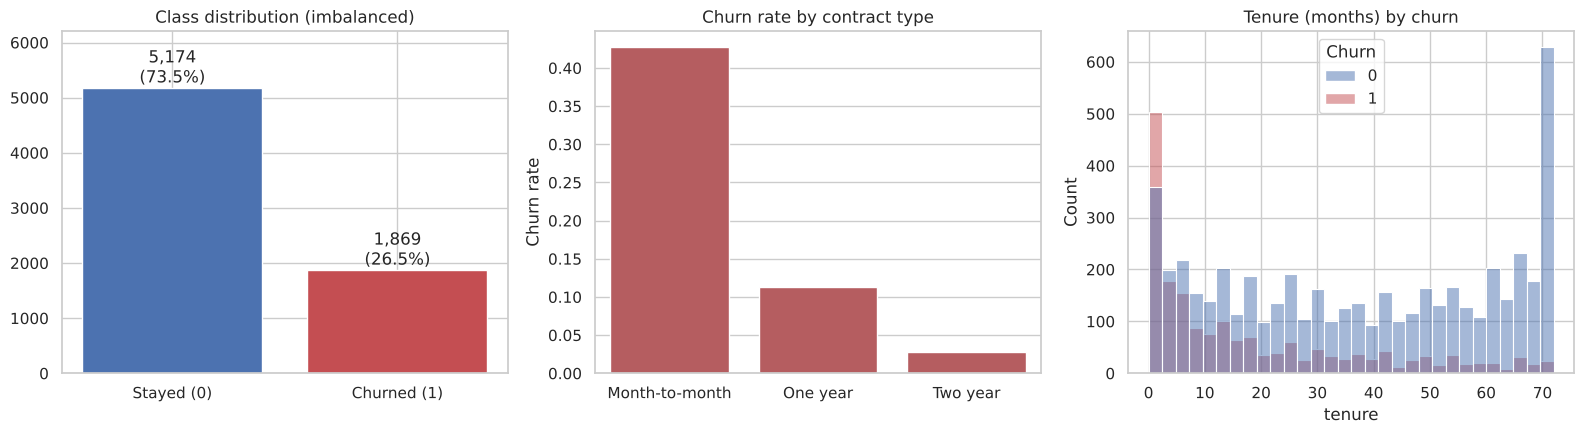

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

counts = df["Churn"].value_counts().sort_index()
axes[0].bar(["Stayed (0)", "Churned (1)"], counts.values, color=["#4c72b0", "#c44e52"])
for i, value in enumerate(counts.values):
    axes[0].text(i, value, f"{value:,}\n({value / len(df):.1%})", ha="center", va="bottom")
axes[0].set_title("Class distribution (imbalanced)")
axes[0].set_ylim(0, counts.max() * 1.2)

by_contract = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
sns.barplot(x=by_contract.index, y=by_contract.values, ax=axes[1], color="#c44e52")
axes[1].set_title("Churn rate by contract type")
axes[1].set_ylabel("Churn rate")
axes[1].set_xlabel("")

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="layer",
             palette=["#4c72b0", "#c44e52"], ax=axes[2])
axes[2].set_title("Tenure (months) by churn")

plt.tight_layout()
save_fig("eda_churn.png")
plt.show()

**Observations**
- Only about **26.5%** of the customers churn, so the classes are imbalanced. A model that always predicts "stayed" would already reach about 73% accuracy, which is why **accuracy is a misleading metric** here and ROC-AUC, recall and precision matter more.
- Customers on **month-to-month contracts** and with a **short tenure** churn far more often.

## 4. Train/test split and preprocessing

The split is **stratified** (both parts keep the 26.5% churn rate). Preprocessing lives in a pipeline, so it is fitted on training data only (also inside every cross-validation fold):
- numeric columns: **median imputation**
- categorical columns: **one-hot encoding** (`OneHotEncoder`, unseen categories are ignored)
- `SeniorCitizen` is already 0/1 and passes through

In [6]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
binary_features = ["SeniorCitizen"]
categorical_features = [
    c for c in df.columns
    if c not in numeric_features + binary_features + ["Churn"]
]
print(f"{len(categorical_features)} categorical features:", categorical_features)

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"\nTrain: {len(X_train)} rows (churn {y_train.mean():.1%}) | "
      f"Test: {len(X_test)} rows (churn {y_test.mean():.1%})")


def build_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("bin", "passthrough", binary_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ])

15 categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train: 5634 rows (churn 26.5%) | Test: 1409 rows (churn 26.5%)


## 5. Handling the class imbalance

Three strategies are compared for each algorithm:
1. **No balancing** (baseline)
2. **Class weighting:** `class_weight="balanced"` for Random Forest and `scale_pos_weight = negatives / positives` for XGBoost
3. **SMOTE:** creates synthetic churn examples by interpolating between neighbours. It runs **inside an imbalanced-learn pipeline**, so synthetic samples are only generated from the training part of each fold and never leak into validation or test data.

In [7]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")


def forest(**kwargs):
    return RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                  random_state=RANDOM_STATE, n_jobs=-1, **kwargs)


def xgboost_model(**kwargs):
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, eval_metric="logloss",
                         random_state=RANDOM_STATE, n_jobs=1, **kwargs)


def plain(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


def with_smote(model):
    return ImbPipeline([("prep", build_preprocessor()),
                        ("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("model", model)])


models = {
    "Random Forest (no balancing)": plain(forest()),
    "Random Forest (class weights)": plain(forest(class_weight="balanced")),
    "Random Forest (SMOTE)": with_smote(forest()),
    "XGBoost (no balancing)": plain(xgboost_model()),
    "XGBoost (scale_pos_weight)": plain(xgboost_model(scale_pos_weight=scale_pos_weight)),
    "XGBoost (SMOTE)": with_smote(xgboost_model()),
}

scale_pos_weight = 2.77


## 6. Cross-validation (5-fold, stratified)

Each model is scored by ROC-AUC on the training set only. The test set stays untouched until the final evaluation.

In [8]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=folds, scoring="roc_auc")
    cv_rows[name] = {"CV ROC-AUC (mean)": scores.mean(), "CV ROC-AUC (std)": scores.std()}

cv_results = pd.DataFrame(cv_rows).T.rename_axis("Model")
display(cv_results.round(4))

,CV ROC-AUC (mean),CV ROC-AUC (std)
Model,,
Random Forest (no balancing),0.8474,0.0093
Random Forest (class weights),0.8475,0.0093
Random Forest (SMOTE),0.8418,0.0095
XGBoost (no balancing),0.8487,0.0099
XGBoost (scale_pos_weight),0.8476,0.0113
XGBoost (SMOTE),0.8482,0.0118


## 7. Final evaluation on the held-out test set

In [9]:
for name, model in models.items():
    model.fit(X_train, y_train)

probabilities = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
predictions = {name: (p >= 0.5).astype(int) for name, p in probabilities.items()}

rows = {}
for name in models:
    rows[name] = {
        "ROC-AUC": roc_auc_score(y_test, probabilities[name]),
        "Avg. precision": average_precision_score(y_test, probabilities[name]),
        "Accuracy": accuracy_score(y_test, predictions[name]),
        "Precision (churn)": precision_score(y_test, predictions[name]),
        "Recall (churn)": recall_score(y_test, predictions[name]),
        "F1 (churn)": f1_score(y_test, predictions[name]),
    }

test_results = pd.DataFrame(rows).T.rename_axis("Model")
display(test_results.round(4))
print("All models above the 0.80 ROC-AUC target:", bool((test_results["ROC-AUC"] > 0.80).all()))

,ROC-AUC,Avg. precision,Accuracy,Precision (churn),Recall (churn),F1 (churn)
Model,,,,,,
Random Forest (no balancing),0.8424,0.6542,0.8048,0.6787,0.5027,0.5776
Random Forest (class weights),0.8418,0.6506,0.7530,0.5230,0.7914,0.6298
Random Forest (SMOTE),0.8355,0.6212,0.7729,0.5637,0.6390,0.5990
XGBoost (no balancing),0.8478,0.6675,0.8062,0.6700,0.5321,0.5931
XGBoost (scale_pos_weight),0.8471,0.6667,0.7488,0.5175,0.7914,0.6258
XGBoost (SMOTE),0.8465,0.6644,0.7906,0.6088,0.5909,0.5997


All models above the 0.80 ROC-AUC target: True


### ROC curves

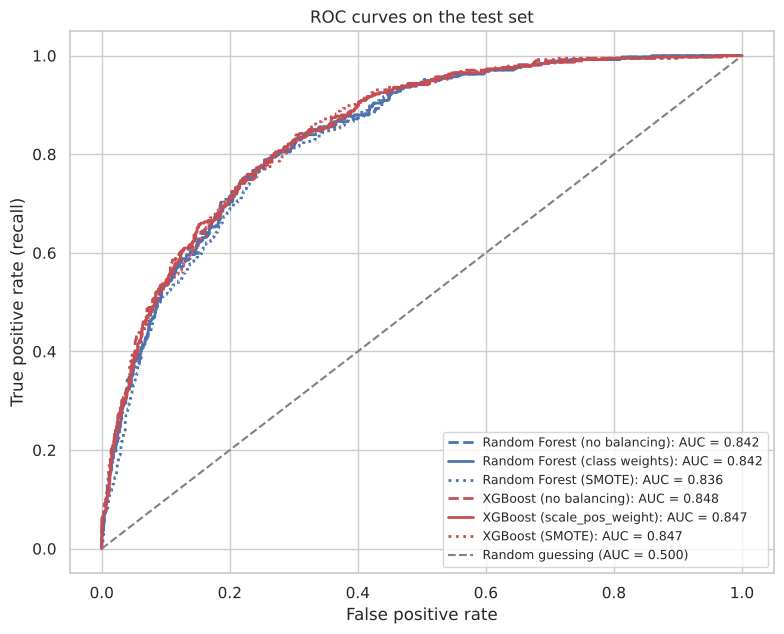

In [10]:
styles = {"no balancing": "--", "class weights": "-", "scale_pos_weight": "-", "SMOTE": ":"}
colors = {"Random Forest": "#4c72b0", "XGBoost": "#c44e52"}

fig, ax = plt.subplots(figsize=(8, 6.5))
for name in models:
    algorithm, strategy = name.split(" (")
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    ax.plot(fpr, tpr, linestyle=styles[strategy.rstrip(")")], color=colors[algorithm], linewidth=2,
            label=f"{name}: AUC = {test_results.loc[name, 'ROC-AUC']:.3f}")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing (AUC = 0.500)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig("roc_curves.png")
plt.show()

### Confusion matrices (decision threshold 0.5)

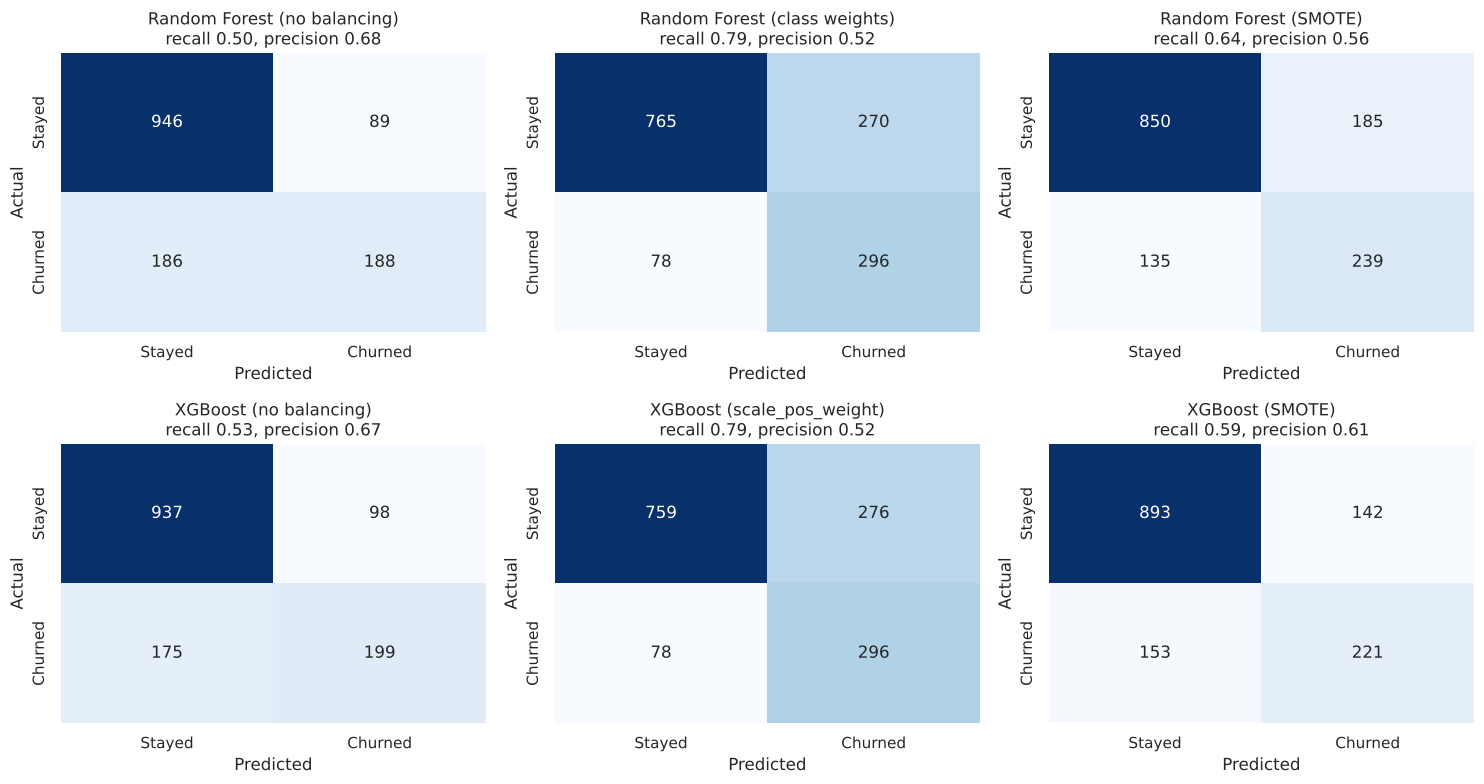

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
    ax.set_title(f"{name}\nrecall {test_results.loc[name, 'Recall (churn)']:.2f}, "
                 f"precision {test_results.loc[name, 'Precision (churn)']:.2f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
save_fig("confusion_matrices.png")
plt.show()

### Precision-recall trade-off (XGBoost with `scale_pos_weight`)

The default threshold of 0.5 is not sacred. For a retention campaign, the threshold decides how many at-risk customers are found (recall) versus how many contacted customers would not have left anyway (precision).

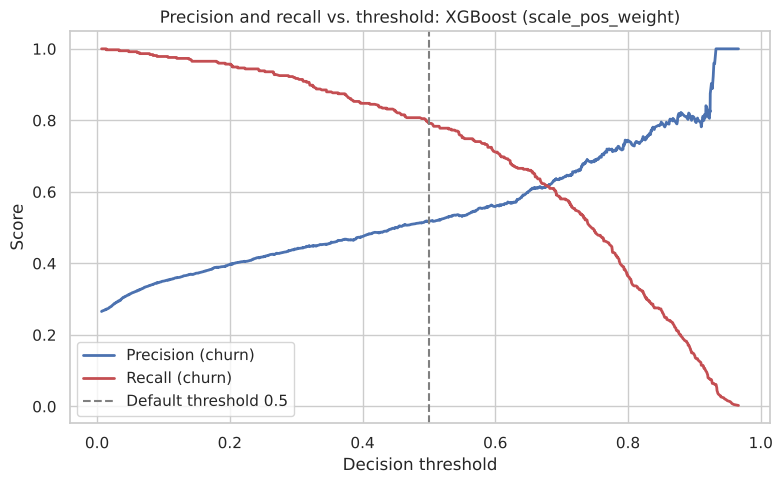

In [12]:
best_name = "XGBoost (scale_pos_weight)"
precision, recall, thresholds = precision_recall_curve(y_test, probabilities[best_name])

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision (churn)", color="#4c72b0", linewidth=2)
plt.plot(thresholds, recall[:-1], label="Recall (churn)", color="#c44e52", linewidth=2)
plt.axvline(0.5, color="grey", linestyle="--", label="Default threshold 0.5")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title(f"Precision and recall vs. threshold: {best_name}")
plt.legend()
plt.tight_layout()
save_fig("threshold_tradeoff.png")
plt.show()

## 8. Top 10 feature importances

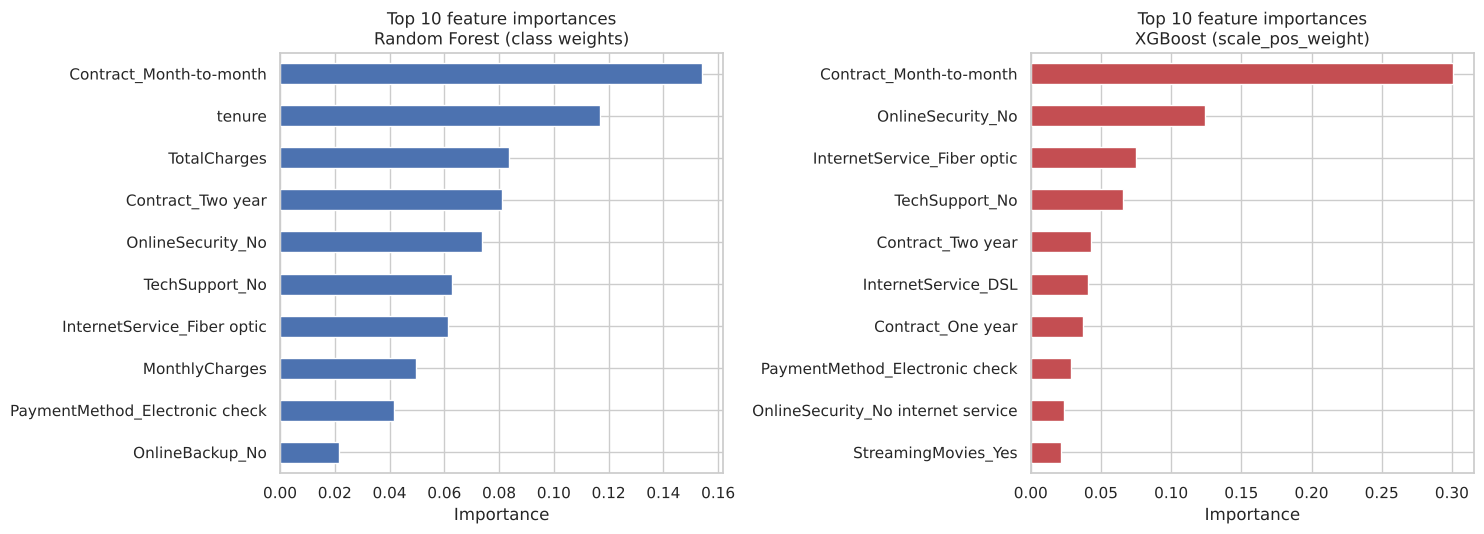


Random Forest (class weights):
Contract_Month-to-month           0.154
tenure                            0.117
TotalCharges                      0.084
Contract_Two year                 0.081
OnlineSecurity_No                 0.074
TechSupport_No                    0.063
InternetService_Fiber optic       0.061
MonthlyCharges                    0.050
PaymentMethod_Electronic check    0.042
OnlineBackup_No                   0.021

XGBoost (scale_pos_weight):
Contract_Month-to-month               0.301
OnlineSecurity_No                     0.124
InternetService_Fiber optic           0.075
TechSupport_No                        0.066
Contract_Two year                     0.043
InternetService_DSL                   0.041
Contract_One year                     0.037
PaymentMethod_Electronic check        0.028
OnlineSecurity_No internet service    0.024
StreamingMovies_Yes                   0.022


In [13]:
def top_importances(model, n=10):
    names = [c.split("__", 1)[1] for c in model.named_steps["prep"].get_feature_names_out()]
    values = pd.Series(model.named_steps["model"].feature_importances_, index=names)
    return values.sort_values(ascending=False).head(n)


importance_models = {
    "Random Forest (class weights)": "#4c72b0",
    "XGBoost (scale_pos_weight)": "#c44e52",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (name, color) in zip(axes, importance_models.items()):
    top = top_importances(models[name])
    top.sort_values().plot(kind="barh", ax=ax, color=color)
    ax.set_title(f"Top 10 feature importances\n{name}")
    ax.set_xlabel("Importance")
plt.tight_layout()
save_fig("feature_importance.png")
plt.show()

for name in importance_models:
    print(f"\n{name}:")
    print(top_importances(models[name]).round(3).to_string())

## 9. Conclusion

### Results
- **All six models clear the 0.80 target.** Test ROC-AUC lies between 0.836 and 0.848, and the cross-validated ROC-AUC between 0.842 and 0.849 (standard deviation about 0.01). XGBoost is slightly ahead of Random Forest, but the gap is within the cross-validation noise, so neither algorithm is clearly better here.
- **Balancing barely changes ROC-AUC, because that metric measures how well customers are ranked, not where the 0.5 threshold falls.** What it changes is the decision at that threshold: without balancing, the models find only about 50% to 53% of the customers who churn (recall) while reaching about 80% accuracy. With class weights, recall rises to **0.79** at the cost of precision (0.52) and accuracy (0.75), and the F1-score for churn improves from about 0.58-0.59 to **0.63**.
- **SMOTE did not beat simple class weighting** in this experiment (recall 0.59-0.64, similar F1), and it is slower. Class weights are the simpler and, here, equally good choice.
- **Accuracy is misleading on this dataset:** always predicting "stayed" would already give about 73.5%.

### Feature importance
- In both models, a **month-to-month contract** is the most important feature, followed by **tenure** and **total charges**, missing **online security** and **tech support**, **fiber-optic internet** and paying by **electronic check**. This matches the exploratory analysis.
- Feature importance describes what the model uses, not what causes churn. Impurity-based importances (Random Forest) also tend to favour continuous features such as `tenure` and `TotalCharges`.

### Business perspective
The right decision threshold depends on the cost of missing a churner versus the cost of contacting a customer who would have stayed. The precision-recall plot shows this trade-off.

### Limitations and next steps
- Hyperparameters were set to reasonable fixed values; a search (for example `RandomizedSearchCV`) could improve the scores slightly.
- Use permutation importance or SHAP values for more reliable explanations, and calibrate the predicted probabilities before using them in a retention campaign.
- The test set has 1,409 customers, so differences of one or two points in recall or precision are not conclusive.